In [ ]:
import os
import time
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn import metrics as mt

from xgboost import XGBClassifier

In [ ]:
DATASET_FILE = "22_apps_flow_features.csv"

df = pd.read_csv(DATASET_FILE)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nAvailable apps:")
print(df["ProtocolName"].value_counts())

Dataset shape: (17400, 87)

Columns:
['Flow.ID', 'Source.IP', 'Source.Port', 'Destination.IP', 'Destination.Port', 'Protocol', 'Timestamp', 'Flow.Duration', 'Total.Fwd.Packets', 'Total.Backward.Packets', 'Total.Length.of.Fwd.Packets', 'Total.Length.of.Bwd.Packets', 'Fwd.Packet.Length.Max', 'Fwd.Packet.Length.Min', 'Fwd.Packet.Length.Mean', 'Fwd.Packet.Length.Std', 'Bwd.Packet.Length.Max', 'Bwd.Packet.Length.Min', 'Bwd.Packet.Length.Mean', 'Bwd.Packet.Length.Std', 'Flow.Bytes.s', 'Flow.Packets.s', 'Flow.IAT.Mean', 'Flow.IAT.Std', 'Flow.IAT.Max', 'Flow.IAT.Min', 'Fwd.IAT.Total', 'Fwd.IAT.Mean', 'Fwd.IAT.Std', 'Fwd.IAT.Max', 'Fwd.IAT.Min', 'Bwd.IAT.Total', 'Bwd.IAT.Mean', 'Bwd.IAT.Std', 'Bwd.IAT.Max', 'Bwd.IAT.Min', 'Fwd.PSH.Flags', 'Bwd.PSH.Flags', 'Fwd.URG.Flags', 'Bwd.URG.Flags', 'Fwd.Header.Length', 'Bwd.Header.Length', 'Fwd.Packets.s', 'Bwd.Packets.s', 'Min.Packet.Length', 'Max.Packet.Length', 'Packet.Length.Mean', 'Packet.Length.Std', 'Packet.Length.Variance', 'FIN.Flag.Count', 'SYN

In [ ]:
os.makedirs("Features", exist_ok=True)
os.makedirs("Figures", exist_ok=True)
os.makedirs("Results", exist_ok=True)

print("Folders created.")

Folders created.


In [ ]:
APP_NAMES = ["SKYPE", "DROPBOX", "GOOGLE"]

FEATURE_COLUMNS = [
    "Fwd.Packet.Length.Mean",
    "Fwd.Packet.Length.Max",
    "Fwd.Packet.Length.Min",
    "Fwd.IAT.Mean",
    "Fwd.IAT.Max",
    "Fwd.IAT.Min",
    "Bwd.Packet.Length.Mean",
    "Bwd.Packet.Length.Max",
    "Bwd.Packet.Length.Min",
    "Bwd.IAT.Mean",
    "Bwd.IAT.Max",
    "Bwd.IAT.Min",
    "Packet.Length.Mean",
    "Max.Packet.Length",
    "Min.Packet.Length",
    "Flow.IAT.Mean",
    "Flow.IAT.Max",
    "Flow.IAT.Min",
    "Flow.Bytes.s",
    "Flow.Packets.s"
]

LABEL_MAP = {
    "SKYPE": 0,
    "DROPBOX": 1,
    "GOOGLE": 2
}

CLASS_NAMES = ["SKYPE", "DROPBOX", "GOOGLE"]

print("Apps:", APP_NAMES)
print("Number of features:", len(FEATURE_COLUMNS))

Apps: ['SKYPE', 'DROPBOX', 'GOOGLE']
Number of features: 20


In [ ]:
def create_dataset(dataset_filename, app_names):
    df = pd.read_csv(dataset_filename)

    df_apps = df[df["ProtocolName"].isin(app_names)].copy()

    selected_columns = FEATURE_COLUMNS + ["ProtocolName"]
    df_apps = df_apps[selected_columns]

    df_apps.replace([np.inf, -np.inf], np.nan, inplace=True)
    df_apps.dropna(inplace=True)
    df_apps.drop_duplicates(inplace=True)

    negative_values = (df_apps[FEATURE_COLUMNS] < 0).sum().sum()
    print("Number of negative values:", negative_values)

    output_filename = "Features/features_" + "_".join(app_names) + ".csv"
    df_apps.to_csv(output_filename, index=False)

    print("Dataset saved in:", output_filename)
    print("Shape:", df_apps.shape)
    print("\nClass counts:")
    print(df_apps["ProtocolName"].value_counts())

    return output_filename

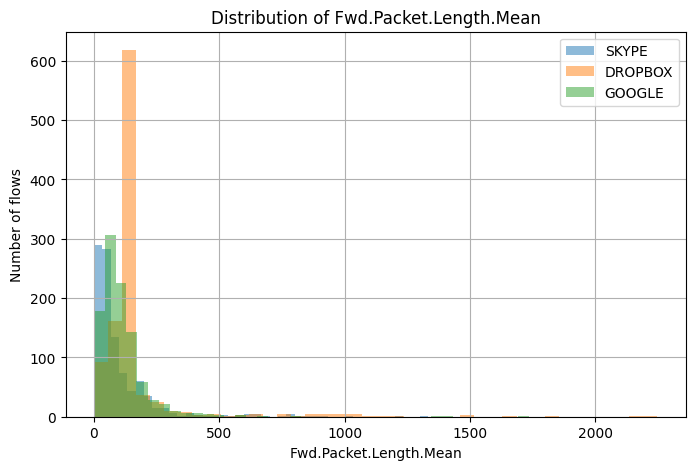

Saved: Figures/distribution_Fwd_Packet_Length_Mean.png


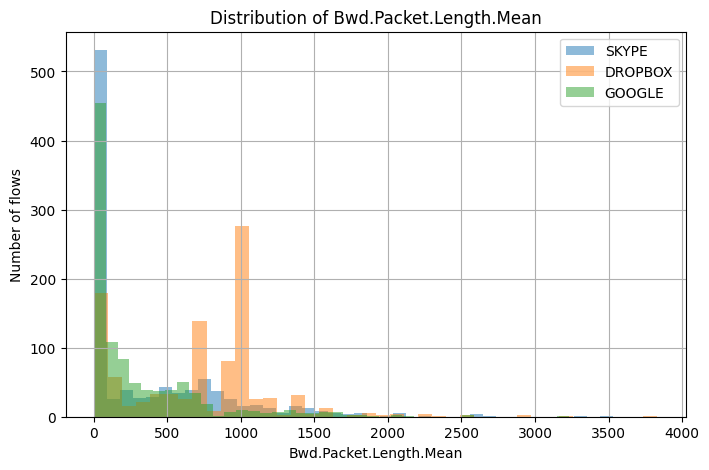

Saved: Figures/distribution_Bwd_Packet_Length_Mean.png


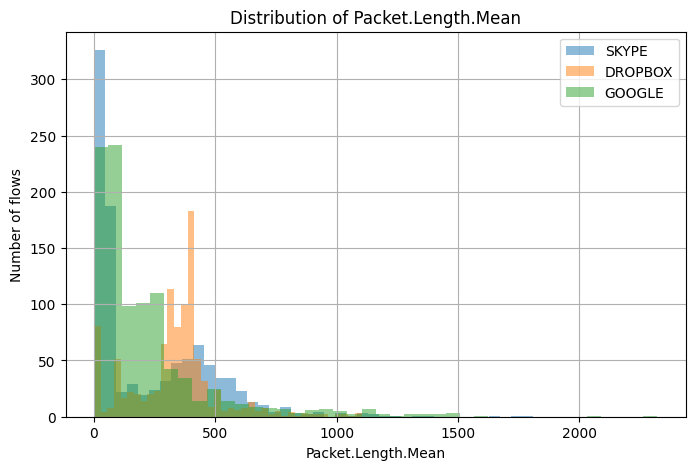

Saved: Figures/distribution_Packet_Length_Mean.png


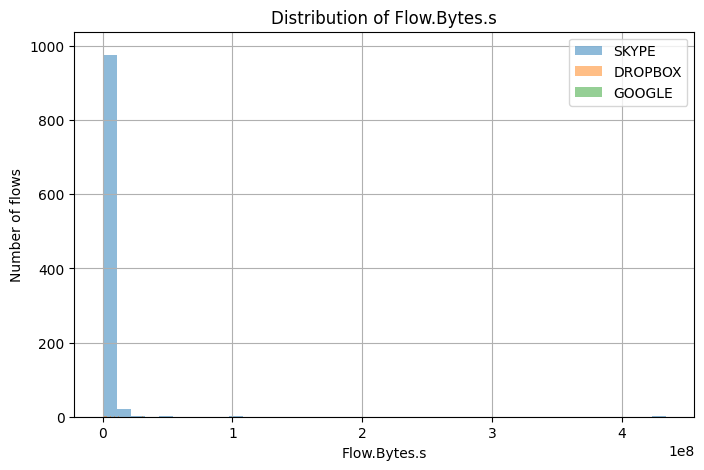

Saved: Figures/distribution_Flow_Bytes_s.png


In [ ]:
def plot_feature_distribution(dataset_file, app_names, features_to_plot):
    df = pd.read_csv(dataset_file)

    for feature in features_to_plot:
        plt.figure(figsize=(8, 5))

        for app in app_names:
            values = df[df["ProtocolName"] == app][feature]
            plt.hist(values, bins=40, alpha=0.5, label=app)

        plt.xlabel(feature)
        plt.ylabel("Number of flows")
        plt.title("Distribution of " + feature)
        plt.legend()
        plt.grid(True)

        safe_feature_name = feature.replace(".", "_").replace("/", "_")
        output_path = f"Figures/distribution_{safe_feature_name}.png"
        plt.savefig(output_path, bbox_inches="tight")
        plt.show()

        print("Saved:", output_path)


features_to_plot = [
    "Fwd.Packet.Length.Mean",
    "Bwd.Packet.Length.Mean",
    "Packet.Length.Mean",
    "Flow.Bytes.s"
]

plot_feature_distribution(homework_dataset_file, APP_NAMES, features_to_plot)

In [ ]:
def load_dataset(app_names):
    dataset_file = "Features/features_" + "_".join(app_names) + ".csv"

    df = pd.read_csv(dataset_file)

    X = df[FEATURE_COLUMNS].values
    y = df["ProtocolName"].map(LABEL_MAP).values

    return X, y


X, y = load_dataset(APP_NAMES)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Labels:", np.unique(y, return_counts=True))

X shape: (3000, 20)
y shape: (3000,)
Labels: (array([0, 1, 2]), array([1000, 1000, 1000]))


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Full dataset:", X.shape, y.shape)
print("Train dataset:", X_train.shape, y_train.shape)
print("Test dataset:", X_test.shape, y_test.shape)

print("\nFull class counts:", np.unique(y, return_counts=True))
print("Train class counts:", np.unique(y_train, return_counts=True))
print("Test class counts:", np.unique(y_test, return_counts=True))

Full dataset: (3000, 20) (3000,)
Train dataset: (2400, 20) (2400,)
Test dataset: (600, 20) (600,)

Full class counts: (array([0, 1, 2]), array([1000, 1000, 1000]))
Train class counts: (array([0, 1, 2]), array([800, 800, 800]))
Test class counts: (array([0, 1, 2]), array([200, 200, 200]))


In [ ]:
scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

print("Standardized train shape:", X_train_std.shape)
print("Standardized test shape:", X_test_std.shape)

Standardized train shape: (2400, 20)
Standardized test shape: (600, 20)


In [ ]:
def train_classifier_logistic(X_train, y_train):
    regularization_values = [0.01, 0.1, 1, 10, 100, 1000]
    max_iter_values = [1000, 3000, 5000]

    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    scores = np.zeros((len(regularization_values), len(max_iter_values)))

    best_score = -1
    best_regularization = None
    best_max_iter = None

    start_cv = time.time()

    for i, regularization in enumerate(regularization_values):
        for j, max_iter in enumerate(max_iter_values):

            fold_scores = []

            for train_index, val_index in kf.split(X_train):
                X_tr = X_train[train_index]
                X_val = X_train[val_index]
                y_tr = y_train[train_index]
                y_val = y_train[val_index]

                model = LogisticRegression(
                    C=regularization,
                    max_iter=max_iter,
                    solver="lbfgs"
                )

                model.fit(X_tr, y_tr)
                y_val_pred = model.predict(X_val)

                score = mt.accuracy_score(y_val, y_val_pred)
                fold_scores.append(score)

            mean_score = np.mean(fold_scores)
            scores[i, j] = mean_score

            if mean_score > best_score:
                best_score = mean_score
                best_regularization = regularization
                best_max_iter = max_iter

    end_cv = time.time()

    print("Crossval time [s]:", round(end_cv - start_cv, 3))
    print("Best hyperparams:")
    print({
        "regularization": best_regularization,
        "max_iter": best_max_iter,
        "score": best_score
    })

    print("\nScores matrix:")
    print(scores)

    start_train = time.time()

    final_model = LogisticRegression(
        C=best_regularization,
        max_iter=best_max_iter,
        solver="lbfgs"
    )

    final_model.fit(X_train, y_train)

    end_train = time.time()

    train_score = final_model.score(X_train, y_train)

    print("\nScore of the final model on train set:", train_score)
    print("Training time [s]:", round(end_train - start_train, 3))

    return final_model


logistic_model = train_classifier_logistic(X_train_std, y_train)

Crossval time [s]: 19.186
Best hyperparams:
{'regularization': 1000, 'max_iter': 1000, 'score': np.float64(0.7608333333333334)}

Scores matrix:
[[0.69416667 0.69416667 0.69416667]
 [0.70708333 0.70708333 0.70708333]
 [0.74458333 0.74458333 0.74458333]
 [0.75416667 0.75416667 0.75416667]
 [0.75958333 0.75958333 0.75958333]
 [0.76083333 0.76083333 0.76083333]]

Score of the final model on train set: 0.7683333333333333
Training time [s]: 0.536


In [ ]:
def train_classifier_XGB(X_train, y_train):
    n_estimators_values = [50, 100, 150]
    max_depth_values = [5, 10, 20]
    subsample_values = [0.7, 0.9, 1.0]

    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    scores = np.zeros((
        len(n_estimators_values),
        len(max_depth_values),
        len(subsample_values)
    ))

    best_score = -1
    best_n_estimators = None
    best_max_depth = None
    best_subsample = None

    start_cv = time.time()

    for i, n_estimators in enumerate(n_estimators_values):
        for j, max_depth in enumerate(max_depth_values):
            for k, subsample in enumerate(subsample_values):

                fold_scores = []

                for train_index, val_index in kf.split(X_train):
                    X_tr = X_train[train_index]
                    X_val = X_train[val_index]
                    y_tr = y_train[train_index]
                    y_val = y_train[val_index]

                    model = XGBClassifier(
                        n_estimators=n_estimators,
                        max_depth=max_depth,
                        subsample=subsample,
                        objective="multi:softmax",
                        num_class=3,
                        eval_metric="mlogloss",
                        random_state=42
                    )

                    model.fit(X_tr, y_tr)
                    y_val_pred = model.predict(X_val)

                    score = mt.accuracy_score(y_val, y_val_pred)
                    fold_scores.append(score)

                mean_score = np.mean(fold_scores)
                scores[i, j, k] = mean_score

                if mean_score > best_score:
                    best_score = mean_score
                    best_n_estimators = n_estimators
                    best_max_depth = max_depth
                    best_subsample = subsample

    end_cv = time.time()

    print("Crossval time [s]:", round(end_cv - start_cv, 3))
    print("Best hyperparams:")
    print({
        "n_estimators": best_n_estimators,
        "max_depth": best_max_depth,
        "subsample": best_subsample,
        "score": best_score
    })

    print("\nScores matrix:")
    print(scores)

    start_train = time.time()

    final_model = XGBClassifier(
        n_estimators=best_n_estimators,
        max_depth=best_max_depth,
        subsample=best_subsample,
        objective="multi:softmax",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42
    )

    final_model.fit(X_train, y_train)

    end_train = time.time()

    train_score = final_model.score(X_train, y_train)

    print("\nScore of the final model on train set:", train_score)
    print("Best n_estimators:", best_n_estimators)
    print("Best max_depth:", best_max_depth)
    print("Best subsample:", best_subsample)
    print("Training time [s]:", round(end_train - start_train, 3))

    return final_model


xgb_model = train_classifier_XGB(X_train, y_train)

Crossval time [s]: 114.348
Best hyperparams:
{'n_estimators': 50, 'max_depth': 5, 'subsample': 1.0, 'score': np.float64(0.93)}

Scores matrix:
[[[0.92166667 0.92958333 0.93      ]
  [0.92416667 0.92458333 0.91916667]
  [0.92291667 0.92083333 0.91708333]]

 [[0.92125    0.92916667 0.92916667]
  [0.92666667 0.92625    0.9225    ]
  [0.92458333 0.92375    0.92      ]]

 [[0.92625    0.92791667 0.92916667]
  [0.925      0.92708333 0.925     ]
  [0.92625    0.92541667 0.92208333]]]

Score of the final model on train set: 0.9858333333333333
Best n_estimators: 50
Best max_depth: 5
Best subsample: 1.0
Training time [s]: 0.289


In [ ]:
y_pred_logistic = logistic_model.predict(X_test_std)
y_pred_xgb = xgb_model.predict(X_test)

print("Logistic prediction shape:", y_pred_logistic.shape)
print("XGBoost prediction shape:", y_pred_xgb.shape)

Logistic prediction shape: (600,)
XGBoost prediction shape: (600,)


In [ ]:
def performance_eval(y_true, y_pred, result_filename, class_names):
    accuracy = mt.accuracy_score(y_true, y_pred)
    precision = mt.precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = mt.recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1score = mt.f1_score(y_true, y_pred, average="weighted", zero_division=0)

    confusion_matrix = mt.confusion_matrix(y_true, y_pred)

    report = mt.classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    )

    with open(result_filename, "w") as f:
        f.write("Accuracy: " + str(accuracy) + "\n")
        f.write("Precision: " + str(precision) + "\n")
        f.write("Recall: " + str(recall) + "\n")
        f.write("F1-score: " + str(f1score) + "\n\n")
        f.write("Confusion matrix:\n")
        f.write(str(confusion_matrix))
        f.write("\n\nClassification report:\n")
        f.write(report)

    print("Results saved in:", result_filename)
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1-score:", f1score)
    print("\nConfusion matrix:")
    print(confusion_matrix)
    print("\nClassification report:")
    print(report)

    return accuracy, precision, recall, f1score

In [ ]:
logistic_metrics = performance_eval(
    y_test,
    y_pred_logistic,
    "Results/logistic_regression_results.txt",
    CLASS_NAMES
)

Results saved in: Results/logistic_regression_results.txt
Accuracy: 0.7583333333333333
Precision: 0.7763282299221058
Recall: 0.7583333333333333
F1-score: 0.7575287586562124

Confusion matrix:
[[141  12  47]
 [ 43 134  23]
 [ 20   0 180]]

Classification report:
              precision    recall  f1-score   support

       SKYPE       0.69      0.70      0.70       200
     DROPBOX       0.92      0.67      0.77       200
      GOOGLE       0.72      0.90      0.80       200

    accuracy                           0.76       600
   macro avg       0.78      0.76      0.76       600
weighted avg       0.78      0.76      0.76       600



In [ ]:
xgb_metrics = performance_eval(
    y_test,
    y_pred_xgb,
    "Results/xgboost_results.txt",
    CLASS_NAMES
)

Results saved in: Results/xgboost_results.txt
Accuracy: 0.9133333333333333
Precision: 0.9135449313569859
Recall: 0.9133333333333333
F1-score: 0.9132784275717752

Confusion matrix:
[[176   8  16]
 [  7 187   6]
 [ 11   4 185]]

Classification report:
              precision    recall  f1-score   support

       SKYPE       0.91      0.88      0.89       200
     DROPBOX       0.94      0.94      0.94       200
      GOOGLE       0.89      0.93      0.91       200

    accuracy                           0.91       600
   macro avg       0.91      0.91      0.91       600
weighted avg       0.91      0.91      0.91       600



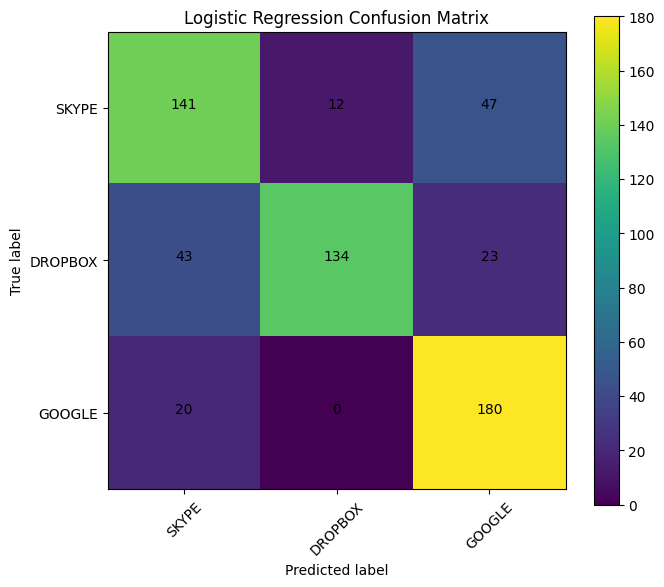

Saved: Figures/logistic_confusion_matrix.png


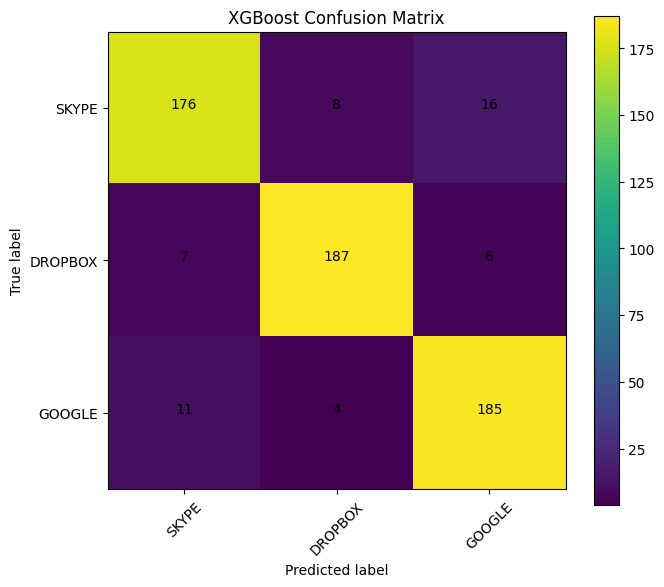

Saved: Figures/xgboost_confusion_matrix.png


In [ ]:
def plot_confusion_matrix(y_true, y_pred, class_names, title, output_path):
    cm = mt.confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(7, 6))
    plt.imshow(cm)
    plt.title(title)
    plt.colorbar()

    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45)
    plt.yticks(tick_marks, class_names)

    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(
            j,
            i,
            cm[i, j],
            horizontalalignment="center"
        )

    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

    print("Saved:", output_path)


plot_confusion_matrix(
    y_test,
    y_pred_logistic,
    CLASS_NAMES,
    "Logistic Regression Confusion Matrix",
    "Figures/logistic_confusion_matrix.png"
)

plot_confusion_matrix(
    y_test,
    y_pred_xgb,
    CLASS_NAMES,
    "XGBoost Confusion Matrix",
    "Figures/xgboost_confusion_matrix.png"
)

In [ ]:
comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression", "XGBoost"],
    "Accuracy": [logistic_metrics[0], xgb_metrics[0]],
    "Precision": [logistic_metrics[1], xgb_metrics[1]],
    "Recall": [logistic_metrics[2], xgb_metrics[2]],
    "F1-score": [logistic_metrics[3], xgb_metrics[3]]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.758333,0.776328,0.758333,0.757529
1,XGBoost,0.913333,0.913545,0.913333,0.913278


# Conclusion

In this homework, I repeated the application traffic identification lab for a multi-class classification problem.

The three applications used were SKYPE, DROPBOX, and GOOGLE. I created a new dataset containing only these three applications and selected 20 traffic-flow features. I also cleaned the data by replacing infinite values, removing missing values, dropping duplicate rows, and checking for negative values. The final homework dataset contains 3000 samples: 1000 SKYPE flows, 1000 DROPBOX flows, and 1000 GOOGLE flows.

After loading the dataset, I assigned numerical labels to the classes: SKYPE = 0, DROPBOX = 1, and GOOGLE = 2. Then, I split the data into training and test sets using a stratified 80/20 split. This kept the dataset balanced: each class had 800 training samples and 200 test samples.

I visualized the distribution of some traffic features. The plots show that some feature distributions overlap between the three applications, so the classification problem is not perfectly simple.

I trained and evaluated two classifiers: Logistic Regression and XGBoost. Logistic Regression was trained using standardized features, while XGBoost was trained using the original non-standardized features.

On the test set, Logistic Regression reached an accuracy of 0.758, precision of 0.776, recall of 0.758, and F1-score of 0.758. XGBoost reached an accuracy of 0.913, precision of 0.914, recall of 0.913, and F1-score of 0.913.

The confusion matrices also confirm that XGBoost performs better. Logistic Regression made more classification mistakes, especially for SKYPE and DROPBOX, while XGBoost correctly classified most samples from all three classes.

Therefore, XGBoost is the better model for this multi-class application traffic identification task. This is expected because Logistic Regression is mainly a linear classifier, while XGBoost can learn more complex and non-linear relationships between the traffic-flow features and the application labels.